# Mutation frequency across binding-affinity bins

Bins genotypes by their affinity for one antigen and reports, within each bin, the fraction of genotypes carrying each of the ten mutations. This script shows which mutations become more common as affinity to one antigen rises and which drop out, which is how the S56R and T57P split in 1NC9 was characterized.

Bin width, affinity ranges for either antigen, and which sites to outline are all arguments.

### **House Keeping**

In [ ]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
import random
import itertools
import warnings
import math
warnings.filterwarnings('ignore')

In [ ]:
###### Geneerate Label Assignment And Conversion Methods based on the Meta_Df
IMGT_column = 'imgt_position'
Kabat_column = 'kabat_position'
sites_column = 'site'
germline_col = 'germline_aa'
mature_col = 'mature_aa'

### Generates mapping for G#M notation (germline identity)+(Position #)+(mature identity)
def mutation_convert_label(meta_in,
                           position_col = Kabat_column,
                           sites_col = sites_column,
                           g_col = germline_col,
                           m_col = mature_col):
  mapping = {}
  for row, site in enumerate(meta_in[sites_col].values):
    mapping[f'{site}'] = f'{meta_in.loc[row,f'{g_col}']}{meta_in.loc[row,f'{position_col}']}{meta_in.loc[row,f'{m_col}']}'
  return mapping

In [ ]:
data_dir = "../data"
fig_dir = "../figures"
table_dir = "../tables"
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(table_dir, exist_ok=True)
png_dpi = 300

plt.rcParams["svg.fonttype"] = "path"   # illustrator drops live text, see the project export note
plt.rcParams["pdf.fonttype"] = 42

bnAb_list = ['1NC9','CH235.12','N49P7','NIH45-46','VRC-PG20','VRC01','VRC07','VRC13','VRC16']

# display name to file stem; the hyphens and the dot do not appear in any filename
name_to_stem = {'1NC9':'1NC9','CH235.12':'CH235_12','N49P7':'N49P7','NIH45-46':'NIH4546',
                'VRC-PG20':'VRCPG20','VRC01':'VRC01','VRC07':'VRC07','VRC13':'VRC13',
                'VRC16':'VRC16'}

rep_avg_cols = ['id','vh_aa'] + [f'site_{i}' for i in range(10)] + ['antigen']


def save_figure(stem):
    """Write the current figure to png, pdf and svg, then check the svg has no live text."""
    name = re.sub(r"[^A-Za-z0-9._-]+", "_", stem).strip("_")
    path = f"{fig_dir}/{name}"
    plt.savefig(f"{path}.png", dpi=png_dpi, bbox_inches="tight")
    plt.savefig(f"{path}.pdf", bbox_inches="tight")
    plt.savefig(f"{path}.svg", bbox_inches="tight")
    assert open(f"{path}.svg").read().count("<text") == 0, "live text in svg, check svg.fonttype"


kds_dict = {}; kds_dict_rep_avg = {}; meta_dict = {}
CH_all_dict = {}; SF_all_dict = {}; CH_params_dict = {}; SF_params_dict = {}
for name in bnAb_list:
    stem = name_to_stem[name]
    kds = pd.read_csv(f"{data_dir}/{stem}_kds.csv")
    kds_dict[name] = kds
    kds_dict_rep_avg[name] = kds.groupby(by=rep_avg_cols).agg({'nlog10_Kd':'mean'}).reset_index()
    meta_dict[name] = pd.read_csv(f"{data_dir}/{stem}_meta.csv")
    CH_all_dict[name] = pd.read_csv(f"{data_dir}/{stem}_CH505TF_BEST_df_all.csv")
    SF_all_dict[name] = pd.read_csv(f"{data_dir}/{stem}_SF162_BEST_df_all.csv")
    CH_params_dict[name] = pd.read_csv(f"{data_dir}/{stem}_CH505TF_BEST_df_params.csv")
    SF_params_dict[name] = pd.read_csv(f"{data_dir}/{stem}_SF162_BEST_df_params.csv")

In [ ]:
kds_dict_rep_avg['VRC16']

,id,vh_aa,site_0,site_1,site_2,site_3,site_4,site_5,site_6,site_7,site_8,site_9,antigen,nlog10_Kd
0,VRC16_var_1,EVQLSESGGGLVKPGGSLRLSCEASGFTFSNYAMGWVRQAPGKGLE...,G,G,G,G,G,G,G,G,G,G,CH505TF,6.000000
1,VRC16_var_1,EVQLSESGGGLVKPGGSLRLSCEASGFTFSNYAMGWVRQAPGKGLE...,G,G,G,G,G,G,G,G,G,G,SF162,6.688642
2,VRC16_var_10,EVQLSESGGGLVKPGGSLRLSCEASGFTFSNYAMGWVRQAPGKGLE...,G,G,G,G,G,G,G,G,M,M,SF162,6.599001
3,VRC16_var_100,EVQLSESGGGLVKPGGSLRLSCEASGFTFSNYAMGWVRQAPGKGLE...,G,G,G,G,G,G,M,M,G,M,SF162,6.670953
4,VRC16_var_101,EVQLSESGGGFVKPGGSLRLSCEASGFTFNNYAMGWVRQAPGKGLE...,M,M,G,M,G,G,G,G,G,G,CH505TF,6.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1687,VRC16_var_97,EVQLSESGGGLVKPGGSLRLSCEASGFTFNNYAMGWVRQAPGKGLE...,G,M,G,G,G,G,G,M,M,G,SF162,6.549344
1688,VRC16_var_98,EVQLSESGGGFVKPGGSLRLSCEASGFTFSNYAMGWVRQAPGKGLE...,M,G,G,G,G,M,G,M,G,G,CH505TF,6.000000
1689,VRC16_var_98,EVQLSESGGGFVKPGGSLRLSCEASGFTFSNYAMGWVRQAPGKGLE...,M,G,G,G,G,M,G,M,G,G,SF162,6.739521
1690,VRC16_var_99,EVQLSESGGGFVKPGGSLRLSCEASGFTFSNYAMGWVRQAPGKGLE...,M,G,G,M,G,G,G,G,G,M,CH505TF,6.000000


### **Functions**

In [ ]:
def site_frequency_by_affinity(bnab: str,
                               antigen: str,
                               m_sites: list = [],
                               CH505TF_range: list = [6,10],
                               SF162_range: list = [6,10],
                               resolution: float = 0.25):

  '''''
  ---- Parameters ----
  bnab: 'bnab name' to be called
  antigen: 'SF162' or 'CH505TF'
  CH505TF_range: in list format with [min, max] Kd, defaults to all data
  SF162_range: in list format with [min, max] Kd, defaults to all data
  resolution: bin width for frequency measure. Defaults to a range of 0.25 Kd

  ---- Outputs ----
  frequencies_compiled: data frame storing the information for the frequency of each mutation in each bin

  N_list: array for the number of data points in each bin. Array length equals number of Kd bins generated according to the resolution

  WT_kds: 2x2 matrix of binding affinity for all germline at 10 sites and all somatic at 10 sites.
          row0 = all g, row1 = all m; col0 = CH505TF, col1 = SF162, such that
          --> [[all_g CH505TF Kd, all_g SF162 Kd],
               [all_m CH505TF Kd, all_m SF162 Kd]]
  '''''
  ##### Data Preparation #####
  ###call data from dictionary for bnab
  kds_df = kds_dict[bnab]
  kds_full = kds_df.copy()
  meta_df = meta_dict[bnab]


  ### assign mutation conditions for a site if relevant

  for site in m_sites:
    kds_df = kds_df[kds_df[f'site_{site}'] == 'M'].copy()

  ### convert to wide form
  kds_wide = kds_df.groupby(['id', 'antigen'])['nlog10_Kd'].mean().unstack().reset_index()
  ### assign antigen range to plot from the function arguments
  if antigen == 'SF162':
    ant_range = SF162_range
  elif antigen == 'CH505TF':
    ant_range = CH505TF_range
  else:
    return "antigen invalid" ## error for typos and invalid antigen names

  ### Recover site identity as individual columns for individual sites on the kds_wide df
  def site_map_to_id(id: str,
                     df = kds_full):
    '''''
    ---- Description ----
    Looped to regenerate site_identity information on the kds_wide df that was lost during the reshaping
    ---- Paramteters ----
    id: str = genotype id in df
    df: object = the dataframe to extract the identity of the 10 positions based on the input id
    ---- Output ----
    df: returns the row from the input df that matches the input id with just the columns for site identity
    '''''
    idx = df[df['id'] == id].index[0]
    df = df.iloc[idx,:].copy()
    return df[[f'site_{i}' for i in range(10)]]

  # initialize a matrix
  sites_info = np.zeros([len(kds_wide),10],dtype = 'str') # rows represent each id in the wide df
                                                          # columns are the 10 positions
  # find all matches - run the site_map_to_id function to recover and store site identity information
  for id in kds_wide['id']:
    idx = kds_wide[kds_wide['id'] == id].index[0]
    sites_info[idx,:] = site_map_to_id(id)

  # add data back to kds_wide as new columns
  kds_wide = kds_wide.assign(
      site_0 = sites_info[:,0],
      site_1 = sites_info[:,1],
      site_2 = sites_info[:,2],
      site_3 = sites_info[:,3],
      site_4 = sites_info[:,4],
      site_5 = sites_info[:,5],
      site_6 = sites_info[:,6],
      site_7 = sites_info[:,7],
      site_8 = sites_info[:,8],
      site_9 = sites_info[:,9])

  ##### Splicing kds_wide into binds #####
  ### Set up bin paramteres
  # find maximum Kd to represent
  max_for_ant = min(np.max(kds_wide[antigen]),ant_range[1]) # choose the higher threshold for creating bins
  max_ceiling = math.ceil(max_for_ant * (1/resolution)) * resolution  ## rounds up to next increment resolution
  # find lowest Kd to represent
  min_for_ant = ant_range[0] # defines the minimum value for the antigen being processed
  min_floor = math.floor(min_for_ant * (1/resolution)) * resolution ## rounds down to the next increment

  ### Generate bin array, where bin width is assigned as the resolution
  bins = np.arange(min_floor,max_ceiling+resolution, resolution) ### creates the array of bin boundaries according to resolution
  ### Begin Splicing kds_wide
  #step1, save WT all_g and all_m data points
  kds_wide['Number of Mature Residues'] = ((kds_wide['site_0'] == 'M').astype(int)+(kds_wide['site_1'] == 'M').astype(int) + (kds_wide['site_2'] == 'M').astype(int) +
    (kds_wide['site_3'] == 'M').astype(int) + (kds_wide['site_4'] == 'M').astype(int)+ (kds_wide['site_5'] == 'M').astype(int) + (kds_wide['site_6'] == 'M').astype(int) +
    (kds_wide['site_7'] == 'M').astype(int) + (kds_wide['site_8'] == 'M').astype(int) +(kds_wide['site_9'] == 'M').astype(int))

  WT_kds = np.zeros([2,2]) #row0 = all g, row1 = all m; col0 = CH, col1 = SF
  WT_kds.fill(np.nan) # Initialize with NaN

  wt_index = kds_wide.index[kds_wide['Number of Mature Residues'] == 0]
  if not wt_index.empty:
      all_WT_idx = wt_index[0]
      WT_kds[0,:] = kds_wide.iloc[all_WT_idx,1:3]
  else:
      print(f"Warning: No 'all germline' entry found for {bnab}. WT_kds[0,:] will be NaN.")

  somatic_indices = kds_wide.index[kds_wide['Number of Mature Residues'] == 10]
  if not somatic_indices.empty:
      all_somatic_idx = somatic_indices[0]
      WT_kds[1,:] = kds_wide.iloc[all_somatic_idx,1:3]
  else:
      print(f"Warning: No 'all mature' entry found for {bnab}. WT_kds[1,:] will be NaN.")


  #step2, restrict the data to the interested range threshold according to function arguments
  kds_wide = kds_wide[kds_wide['SF162'] >= SF162_range[0]]
  kds_wide = kds_wide[kds_wide['SF162'] <= SF162_range[1]]
  kds_wide = kds_wide[kds_wide['CH505TF'] >= CH505TF_range[0]]
  kds_wide = kds_wide[kds_wide['CH505TF'] <= CH505TF_range[1]]
  #step3, create array for storing spliced dataframes
  spliced_dfs_arr = np.zeros(len(bins)-1,dtype = 'object')
  for i in range(len(bins)-1):
    spliced_dfs_arr[i] = kds_wide[(kds_wide[antigen] > bins[i]) & (kds_wide[antigen] <= bins[i+1])] # sort by target antigen

  ##### Compile all spliced DataFrames backinto a single dataframe with additional information #####
  ### Generates a DataFrame for storing site identity frequency measures.
  def count_sites(order:int,
                  df):
    '''''
    ---- Parameters ----
    order: integer intput for Nth bin in the array
    df = dataframe in that Nth bin in the array
    ---- Outputs ----
    frequency_per_bin_df: Pandas DataFrame with cols being different types of frequency measures and each row representing each site
            from row 0 to 9 is site_0 to site_9
    '''''
    frequency_measures = np.zeros([10,2]) # col0 = raw count, col1 = normalized fraction within bin, col2 = N

    for i in range(10): # iterate for 10 positions
      frequency_measures[i,0] = list(df[f'site_{i}']).count('M')  # save in column 1 the raw count of site_i
      if len(df) == 0:
        frequency_measures[i,1] = 0 # if there are no data points in the bin, all frequency measures are 0
      else:
        frequency_measures[i,1] = list(df[f'site_{i}']).count('M') / len(df) # record intra-bin normalized % of the mutation

    frequency_per_bin_df = pd.DataFrame(frequency_measures,columns = ['raw_count','bin_fraction' ]) # rename per data type
    frequency_per_bin_df = frequency_per_bin_df.assign(bin_num = order,
                                                        bin_range = 10*[[bins[order],bins[order+1]]], # create a new column storing the bin's range
                                                        site = [f'site_{k}' for k in range(10)]) # create a new column that marks the site each row is recording




    return frequency_per_bin_df

  ### run the function count_sites for each bin and concatenate into a single df
  frequencies_compiled = pd.DataFrame({})
  num_df= len(spliced_dfs_arr)

   # list of each spliced df length
  first_bin = False
  Last_bin = False
  print([len(x) for x in spliced_dfs_arr])
  # trim leading and trailing zero bins
  for i in range(num_df):
    forward_loop_df = spliced_dfs_arr[i]

    reverse_loop_df = spliced_dfs_arr[-(i+1)]
    if first_bin == False and len(forward_loop_df) > 0:
      first_bin = True
      first_idx = i
    if Last_bin == False and len(reverse_loop_df) > 0:
      Last_bin = True
      Last_idx = num_df-(i+1)
  print(f'first bin = {first_idx} last bin = {Last_idx}')
  N_list = []
  for i in range(first_idx, Last_idx+1):
    df = spliced_dfs_arr[i]
    df_temp = count_sites(i,df)
    N_list.append(len(df))
    frequencies_compiled = pd.concat([frequencies_compiled,df_temp])

  return frequencies_compiled, N_list, WT_kds

### Provides a reference scatter plot that indicates what section of the data is being examined
def ant_ant(bnab,CH_range,SF_range,m_sites: list = []):
  ## add randomized jitter to floored measurements to improve clarity
  def jitter(df):
    np.random.seed(12)
    for i,Kd in enumerate(df['nlog10_Kd']):
      if Kd == 6:
        df.loc[i,'nlog10_Kd'] = Kd - (np.random.random()*.3) -.1

    return df

  # call raw data
  kds_df = kds_dict[bnab].copy()
  filtered_df = kds_df.copy()
  for ms in m_sites:
    filtered_df = filtered_df[filtered_df[f'site_{ms}'] == 'M'].copy()
  filtered_ids = filtered_df['id'].unique()

  kds_df['n_somatic'] = ((kds_df['site_0'] == 'M').astype(int)+(kds_df['site_1'] == 'M').astype(int) + (kds_df['site_2'] == 'M').astype(int) +
    (kds_df['site_3'] == 'M').astype(int) + (kds_df['site_4'] == 'M').astype(int)+ (kds_df['site_5'] == 'M').astype(int) + (kds_df['site_6'] == 'M').astype(int) +
    (kds_df['site_7'] == 'M').astype(int) + (kds_df['site_8'] == 'M').astype(int) +(kds_df['site_9'] == 'M').astype(int))
  kds_df_wide = kds_df.groupby(['id', 'antigen'])['nlog10_Kd'].mean().unstack().reset_index()
  variant_mature = list(kds_df.groupby('id')['n_somatic'].first())
  kds_df_wide['n_somatic'] = variant_mature

  kds_df_wide['CH505TF'] = kds_df_wide['CH505TF'].apply(lambda x: (x - 0.3*np.random.random() - 0.1) if x == 6 else x)
  kds_df_wide['SF162'] = kds_df_wide['SF162'].apply(lambda x: (x - 0.3*np.random.random() - 0.1) if x == 6 else x)


  background = kds_df_wide.copy()

  # filter site
  kds_color_wide = kds_df_wide.copy()
  kds_color_wide = kds_color_wide[kds_color_wide['id'].isin(filtered_ids)].copy()
  kds_color_wide.reset_index(drop = 'index', inplace = True)

  ### Apply the thresholding for the Kd ranges for SF162 and CH505TF
  if SF_range[0] <= 6:
    kds_color_wide = kds_color_wide[(kds_color_wide['SF162'] >= SF_range[0]-.5) & (kds_color_wide['SF162'] <= SF_range[1])]
  else:
    kds_color_wide = kds_color_wide[(kds_color_wide['SF162'] >= SF_range[0]) & (kds_color_wide['SF162'] <= SF_range[1])]

  if CH_range[0] <= 6:
    kds_color_wide = kds_color_wide[(kds_color_wide['CH505TF'] >= CH_range[0]-.5) & (kds_color_wide['CH505TF'] <= CH_range[1])]
  else:
    kds_color_wide = kds_color_wide[(kds_color_wide['CH505TF'] >= CH_range[0]) & (kds_color_wide['CH505TF'] <= CH_range[1])]
  return background, kds_color_wide




In [ ]:
df, N, _, = site_frequency_by_affinity('N49P7', 'CH505TF', [], [5.6,10],[5.6,10], .4)
N

[0, 0, 0, 2, 30, 564, 211, 1]
first bin = 3 last bin = 7


[2, 30, 564, 211, 1]

In [ ]:
BNAB = '1NC9'
antigen = 'SF162'
CH_range = [6.5,10]
SF_range = [6.5,10]
plot_cols_optio  = ['raw_count','bin_fraction']

def plot(BNAB: str,
         antigen: str,
         CH_range: list = [6,10],
         SF_range: list = [6,10],
         m_sites: list = [],
         color_l = 'tab10',
         plot_col: str = 'raw_count',
         resolution: float = 0.25,
         highlight_sites: list = [],          # <-- NEW: sites to outline
         highlight_color: str = 'black',      # <-- NEW: outline color
         highlight_lw: float = 2.5,           # <-- NEW: outline width
         save_fig: bool = False,
         save_fig_title: str = None,
         present_df: bool = False):
  '''''
  ---- Parameters ----
  BNAB: 'bnab name' to be called
  antigen: 'SF162' or 'CH505TF'
  CH_range: in list format with [min, max] Kd, defaults to all data
  SF162_range: in list format with [min, max] Kd, defaults to all data
  plot_col: 'raw_count' or 'bin_fraction'
  resolution: bin width for frequency measure. Defaults to a range of 0.25 Kd
  highlight_sites: list of site keys (same format as m_sites) to draw an
                   edgeline around in the bar plot, useful for calling out
                   specific sites of interest against the rest
  highlight_color: edgeline color for highlighted site bars
  highlight_lw: edgeline width for highlighted site bars
  save_fig: bool; saves figure if True
  save_fig_title: string input for additional description in the saved figure. Default provides, bnab, antigen, andthe Kd ranges for both antigens
  present_df: boool; returns the plotted df if true.
  ---- Output ----
  Bargraph with a scatter plot
  '''''

  ##### Data Import #####
  #call position label dictionary
  convert_label = mutation_convert_label(meta_dict[BNAB])

  #  convert the raw highlight_sites keys into the same display-label
  highlight_labels = [convert_label[f'site_{site}'] for site in highlight_sites] if highlight_sites else []

  #call site_frequency_by_affinity function to generate the data
  frequencies_compiled_df, n_list_raw, WT_kds = site_frequency_by_affinity(BNAB,antigen,CH505TF_range= CH_range,SF162_range= SF_range,resolution = resolution,m_sites=m_sites)
  # Get the original bin_num values that are present in the dataframe
  original_bin_nums_in_df = frequencies_compiled_df['bin_num'].drop_duplicates().sort_values().values

  # Create a new n_list that corresponds precisely to the bins present in the dataframe

  # Prepare unique_bin_labels DataFrame for plotting, re-indexing its bin_num column
  unique_bin_labels = frequencies_compiled_df.drop_duplicates(subset=['bin_num']).sort_values('bin_num').copy() # .copy() to avoid SettingWithCopyWarning
  unique_bin_labels['bin_num'] = range(len(unique_bin_labels))

  #call ant_ant to call scatter plot information
  scatter_bg, scater_wide = ant_ant(BNAB,CH_range,SF_range, m_sites = m_sites)
  # apply labeling correction.
  frequencies_compiled_df['site'] = frequencies_compiled_df['site'].apply(lambda x: convert_label[x])
  # set x-axis labelings

  # fix the hue order
  # containers back to site names
  site_order = list(frequencies_compiled_df['site'].drop_duplicates())

  if plot_col == 'raw_count':
    unique_bin_labels['bin_label'] = unique_bin_labels['bin_range'].apply(lambda x: f'{x[0]:.2f}-{x[1]:.2f}')
  elif plot_col == 'bin_fraction':
    new_labels = []
    # Use n_list_raw, which is now guaranteed to match the length of unique_bin_labels
    for order, n_val, bin_range in zip(original_bin_nums_in_df, n_list_raw, unique_bin_labels['bin_range']):
      if order== 0:
        new_labels.append(f'≤6\nN = {int(n_val)}')
      else:
        new_labels.append(f'{bin_range[0]+.01:.2f}-{bin_range[1]:.2f}\nN = {int(n_val)}')

    unique_bin_labels['bin_label'] = new_labels

  #call subplots
  fig, axes = plt.subplots(1,2,figsize=(24, 7),width_ratios=[2.5,1]) # Adjust figure size for better readability

  #### bar


  # only plot horizontal line for whole data set if raw_count is the y-axis
  if plot_col == 'raw_count':
    # Plot n_list as horizontal lines across each bin, without vertical connectors
    x_coords = unique_bin_labels['bin_num']
    x_plot = []
    y_plot = []
    for i, bin_idx in enumerate(x_coords):
        # Start of the horizontal segment for this bin, aligned with bar start
        x_plot.append(bin_idx - 0.45)
        y_plot.append(n_list_raw[i])
        # End of the horizontal segment for this bin, aligned with bar end
        x_plot.append(bin_idx + 0.45)
        y_plot.append(n_list_raw[i])
        # Insert NaN to break the line between this segment and the next
        x_plot.append(np.nan)
        y_plot.append(np.nan)
    axes[0].plot(x_plot, y_plot, color='red', linestyle='--', label='Total Samples per Bin', linewidth=2)
    axes[0].plot(x_plot, [coor/2 for coor in y_plot], color='magenta', alpha = 0.8,linestyle='--', label='50% Frequency', linewidth=1.5) # 50% line

  # Plot  WT
  print(WT_kds)
  if np.isnan(WT_kds[0,0]) == False:
    axes[1].scatter(x=[WT_kds[0,1]],y=[WT_kds[0,0]],color = 'k', marker='o', s=50, label='All Germline', zorder=3)
  else:
    ##plot inferred
    # call tobit
    CH_tobit_df = CH_all_dict[BNAB]; SF_tobit_df = SF_all_dict[BNAB]
    CH_tobit_df = CH_tobit_df[CH_tobit_df['genotype_tokens'] == 10*'M'].copy()
    SF_tobit_df = SF_tobit_df[SF_tobit_df['genotype_tokens'] == 10*'M'].copy()
    axes[1].scatter(x = SF_tobit_df['predicted_kd_full'], y = CH_tobit_df['predicted_kd_full'],
              marker='o', facecolors = 'white', edgecolors = 'k', linewidth = 1, s=100, zorder=3, label = 'Inferred All Germline')

  if np.isnan(WT_kds[1,0]) == False:
    axes[1].scatter(x=[WT_kds[1,1]],y=[WT_kds[1,0]],color = 'k', marker='*', s= 100, label='All Somatic', zorder=3)
  elif np.isnan(WT_kds[1,0]) == True:
    print('nan')
    ##plot inferred
    # call tobit
    CH_tobit_df = CH_all_dict[BNAB]; SF_tobit_df = SF_all_dict[BNAB]
    CH_tobit_df = CH_tobit_df[CH_tobit_df['genotype_tokens'] == 10*'M'].copy()
    SF_tobit_df = SF_tobit_df[SF_tobit_df['genotype_tokens'] == 10*'M'].copy()
    axes[1].scatter(x = SF_tobit_df['predicted_kd_full'], y = CH_tobit_df['predicted_kd_full'],
              marker='*', facecolors = 'white', edgecolors = 'k', linewidth = 1, s=120, zorder=3, label = 'Inferred All Somatic')


  # Set x-axis ticks to be the bin numbers and then relabel them with the custom bin_labels
  axes[0].set_xticks(ticks=unique_bin_labels['bin_num'], labels=unique_bin_labels['bin_label'])

  #asthetics
  if plot_col == 'bin_fraction':
    axes[0].set(ylim = (0,1.05 ))
  axes[0].set_title(f'Frequency of Mutant Sites by Kd Affinity Range for Antibody {BNAB} (Antigen {antigen})', fontsize = 16, weight = 'bold')
  axes[0].set_axisbelow(True)  # Puts grid below graph elements
  axes[0].grid(axis='y', linestyle='--', alpha=0.7)
  axes[0].axhline(y= .5,linewidth = 2, color = 'red', alpha =.8, linestyle = '--',zorder = 5)
  axes[0].set_yticks(np.arange(0,1.2,0.2))
  axes[0].tick_params(axis = 'y', labelsize = 12,direction = 'inout',width = 2, length = 15)
  axes[0].tick_params(axis = 'x', labelsize = 12)
  axes[0].set_ylabel('Proportion Within Each Range', fontsize = 14)
  axes[0].set_xlabel(f'{antigen} -log$_1$$_0$K$_D$ Ranges', fontsize = 14)

  # plot bar
  # pass hue_order explicitly so we know which container corresponds
  # to which site afterward
  sns.barplot(ax = axes[0], data=frequencies_compiled_df , x='bin_num', y= plot_col, hue='site',
              hue_order = site_order, palette = color_l, zorder = 0, legend = False)

  # outline the bars for any highlighted sites
  if highlight_labels:
    for site_name, container in zip(site_order, axes[0].containers):
      if site_name in highlight_labels:
        for bar in container:
          bar.set_edgecolor(highlight_color)
          bar.set_linewidth(highlight_lw)
          bar.set_zorder(3)
      else:
        for bar in container:
          bar.set_zorder(2)

  site_handles = [container[0] for container in axes[0].containers]
  n_sites = len(site_order)
  n_cols = math.ceil(n_sites / 5)  # forces a 5-row layout regardless of site count
  site_legend = fig.legend(handles=site_handles, labels=site_order, title='Site',
                                ncol=n_cols, loc= (1,1), frameon=True,
                                bbox_to_anchor=(1.003, .7),
                                fontsize=12, title_fontsize=14,
                                columnspacing=4, handletextpad=0.6)

  # re-add the reference-line legend so it isn't dropped by the call above
  if plot_col == 'raw_count':
    line_handles, line_labels = axes[0].get_legend_handles_labels()
  if plot_col == 'raw_count':
    axes[0].add_artist(site_legend)
    axes[0].legend(line_handles, line_labels, loc='upper left', fontsize=9)



  # plot scatter to show what part of the raw data is covered
  sns.scatterplot(ax = axes[1],data = scatter_bg, x = 'SF162', y= 'CH505TF', alpha = .2, color = 'k',size = 'n_somatic', sizes = (5,50), legend = False)
  sns.scatterplot(ax = axes[1],data = scater_wide, x = 'SF162',y = 'CH505TF',color = 'firebrick', size = 'n_somatic', label = 'Data Represented', sizes = (5,50), legend = False)
  axes[1].set(aspect = 'equal')
  axes[1].set_title('Antigen vs. Antigen Binding', fontsize = 16, weight = 'bold' )
  max_val = max(np.max(scatter_bg['SF162']),np.max(scatter_bg['CH505TF']))
  min_val = min(np.min(scatter_bg['SF162']),np.min(scatter_bg['CH505TF']))
  tick_l = np.arange(6,(math.ceil(max_val*2)/2)+0.5,0.5)
  axes[1].set_yticks(tick_l)
  axes[1].set_xticks(tick_l)
  axes[1].set_xlabel(r'SF162 (-log$_1$$_0$K$_D$)', fontsize = 14)
  axes[1].set_ylabel(r'CH505TF (-log$_1$$_0$K$_D$)', fontsize = 14)
  axes[1].tick_params(axis = 'x', length = 15,labelsize = 12,  width = 1.5,direction = 'inout')
  axes[1].tick_params(axis = 'y', length = 15, width = 1.5, labelsize = 12, direction = 'inout' )
  axes[1].set_xticklabels([str(x) if x != 6  else '≤6' for x in tick_l])
  axes[1].set_yticklabels([str(x) if x != 6  else '≤6' for x in tick_l])
  lower_lim = (5.5 if min_val < 6 else 5.9)
  axes[1].plot([lower_lim,max_val],[lower_lim,max_val],color = 'k',alpha = .9, linewidth = '1',linestyle = '--', label = 'Equal Binding')
  axes[1].set_xlim(left = lower_lim, right = None)
  axes[1].set_ylim(bottom = lower_lim, top = None)
  axes[1].axhline(6,color = 'darkgreen',alpha = .7, linewidth = '1',linestyle = ':')
  axes[1].axvline(6,color = 'darkgreen',alpha = .7, linewidth = '1',linestyle = ':',label = 'Assay Threshold')

  scatter_handles, scatter_labels = axes[1].get_legend_handles_labels()
  fig.legend(scatter_handles, scatter_labels, loc=(1,.5),
             bbox_to_anchor=(1.003, 0.4), bbox_transform=fig.transFigure,
             fontsize=12, title='Scatter Plot Key', title_fontsize=14, frameon=True)

  ## store figure given argument is true
  if save_fig is True and save_fig_title is not None:
    save_figure(f'{save_fig_title} {BNAB} {antigen} CH {CH_range} SF {SF_range}')
  elif save_fig is True and save_fig_title is None:
    save_figure(f'{BNAB} {antigen} CH {CH_range} SF {SF_range}')
  else:
    pass

  plt.tight_layout()
  plt.show()
  if present_df == True:
    return frequencies_compiled_df

### **Plot**

[23, 173, 175, 69, 24]
first bin = 0 last bin = 4
[[6.         6.25857416]
 [7.72508029 7.32953504]]


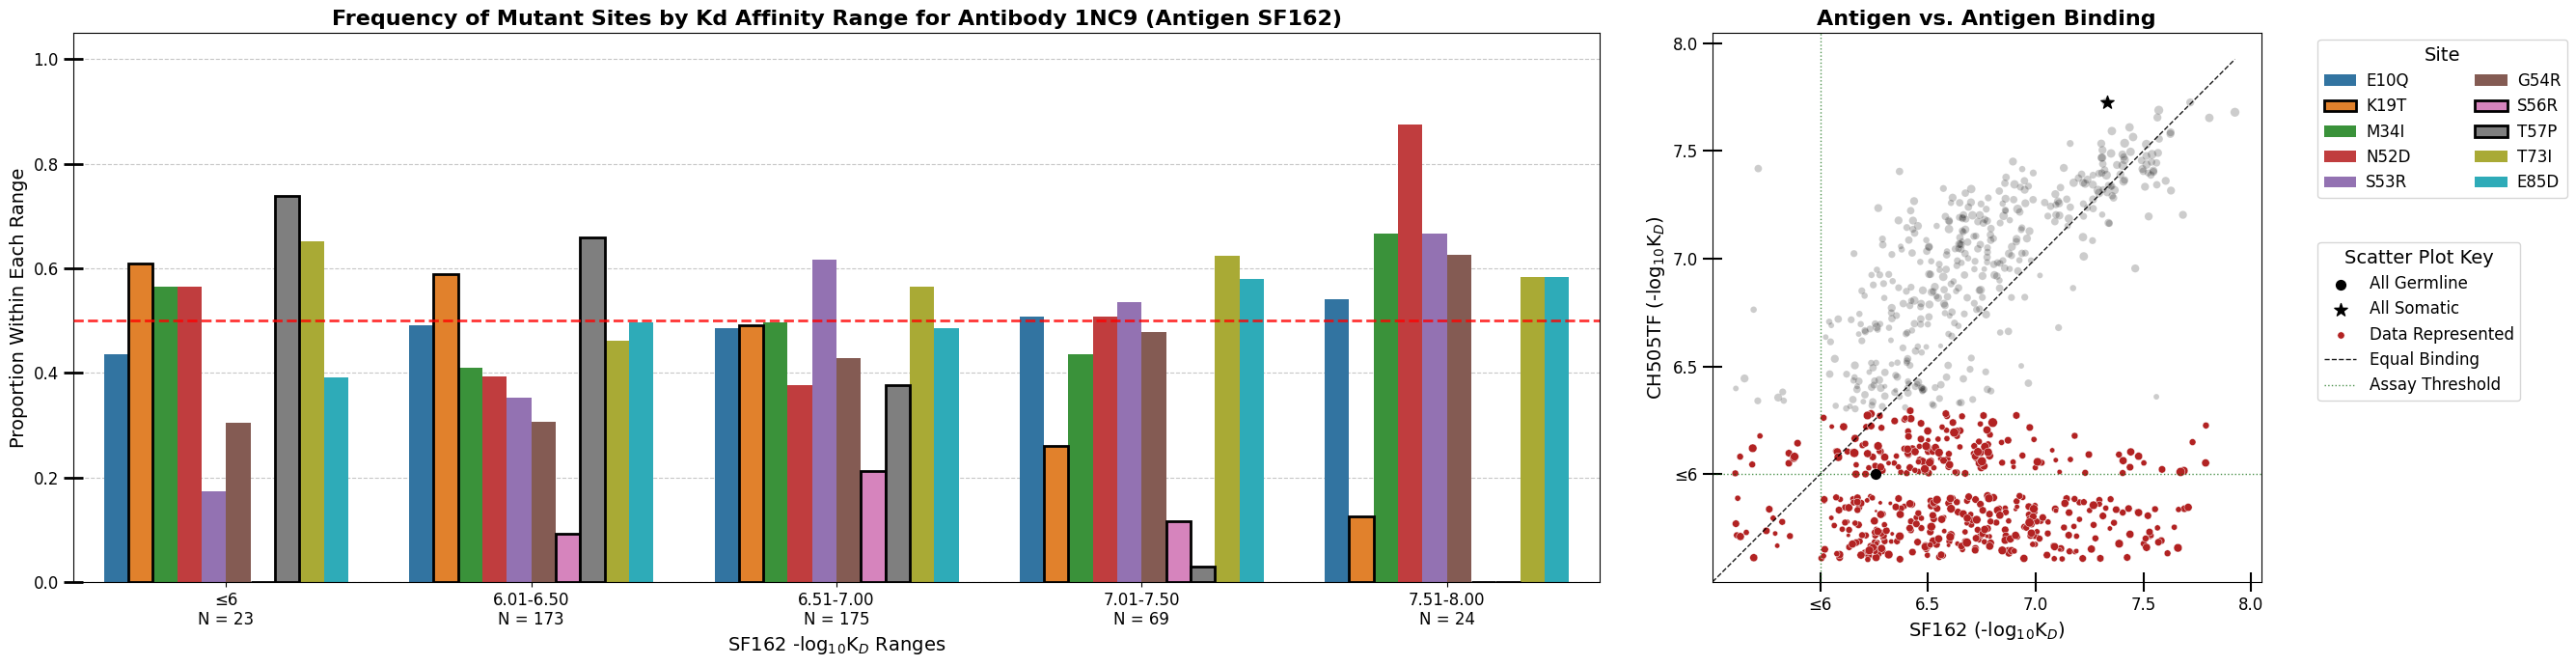

[8, 131, 173, 77, 26]
first bin = 0 last bin = 4
[[6.         6.25857416]
 [7.72508029 7.32953504]]


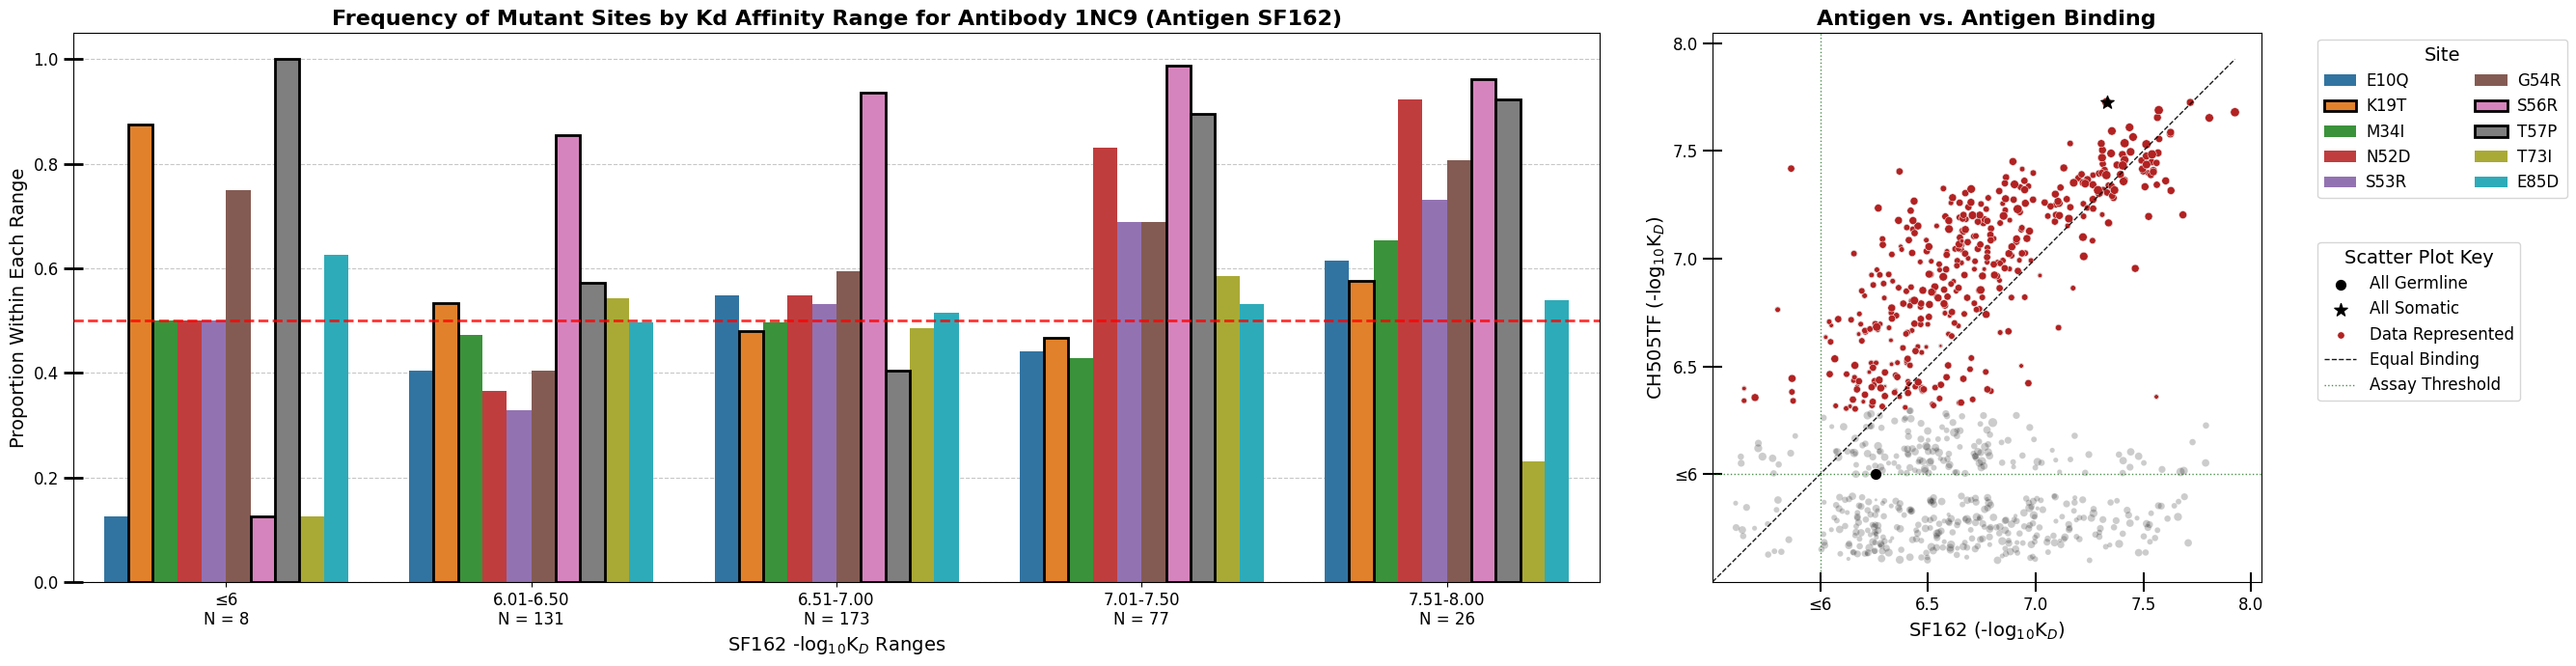

In [ ]:
antigen = 'SF162'
CH_range = [5.5, 6.3]
SF_range = [5.5,10]
plot_cols = ['raw_count','bin_fraction','total_fraction']
bnab = '1NC9'


plot(bnab,antigen,CH_range,SF_range,plot_col = plot_cols[1],
     highlight_sites= [1,6,7], highlight_color='k',highlight_lw=2,
     resolution = .5, color_l='tab10', save_fig = True, save_fig_title = 'Set 1' )

CH_range = [6.3,8]
bnab = '1NC9'
antigen = 'SF162'
plot(bnab,antigen,CH_range,SF_range,plot_col = plot_cols[1],resolution = .5,
     highlight_sites= [1,6,7], highlight_color='k',highlight_lw=2,
     color_l='tab10', save_fig = True, save_fig_title = 'Set 2' )

# SF_range = [6,8.2]
# bnab = 'VRC13'
# antigen = 'CH505TF'
# plot(bnab,antigen,CH_range,SF_range,plot_cols[1],resolution = .25)

In [ ]:
meta_dict['NIH45-46']

,site,chain,kabat_position,imgt_position,region,germline_aa,mature_aa
0,site_0,heavy,19,20,FR1,K,R
1,site_1,heavy,20,21,FR1,V,L
2,site_2,heavy,45,50,FR2,L,P
3,site_3,heavy,51,56,CDR2,I,L
4,site_4,heavy,52,57,CDR2,N,K
5,site_5,heavy,54,62,CDR2,S,G
6,site_6,heavy,56,64,CDR2,G,A
7,site_7,heavy,75,84,FR3,I,S
8,site_8,heavy,80,89,FR3,M,L
9,site_9,heavy,91,103,FR3,Y,F


[22, 106, 102, 83, 56, 25, 2]
first bin = 0 last bin = 6
[[       nan        nan]
 [6.19835663 7.14013515]]


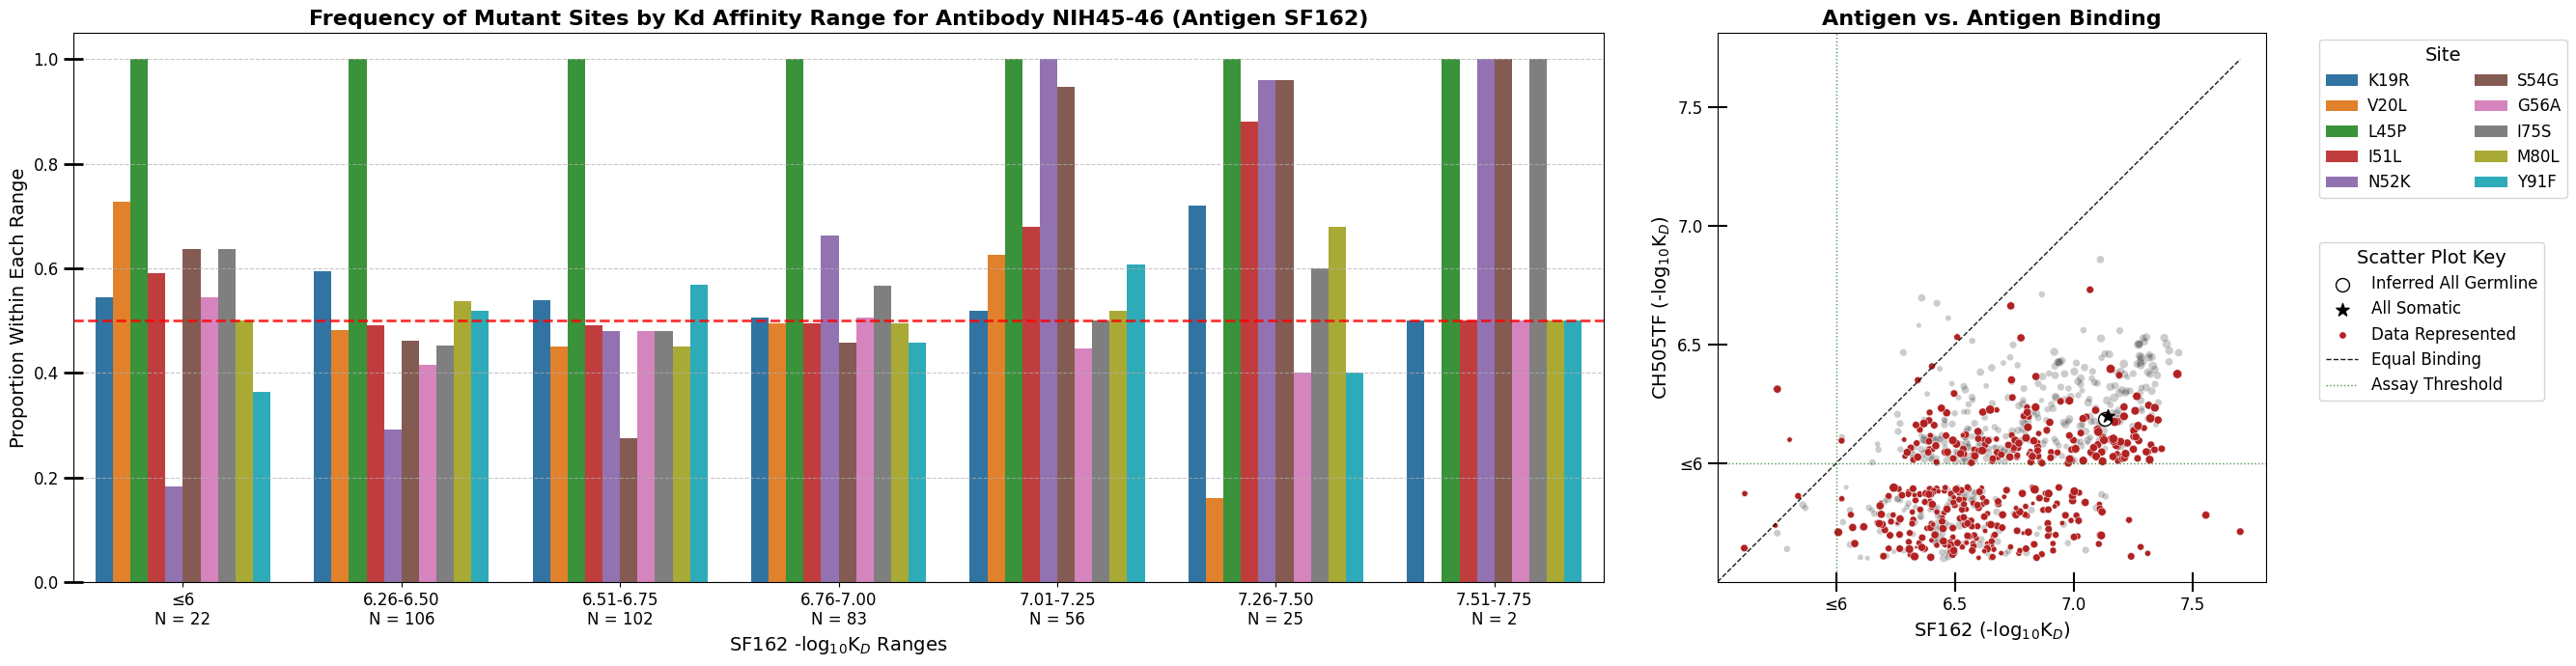

[24, 107, 95, 71, 78, 14]
first bin = 0 last bin = 5
[[       nan        nan]
 [6.19835663 7.14013515]]


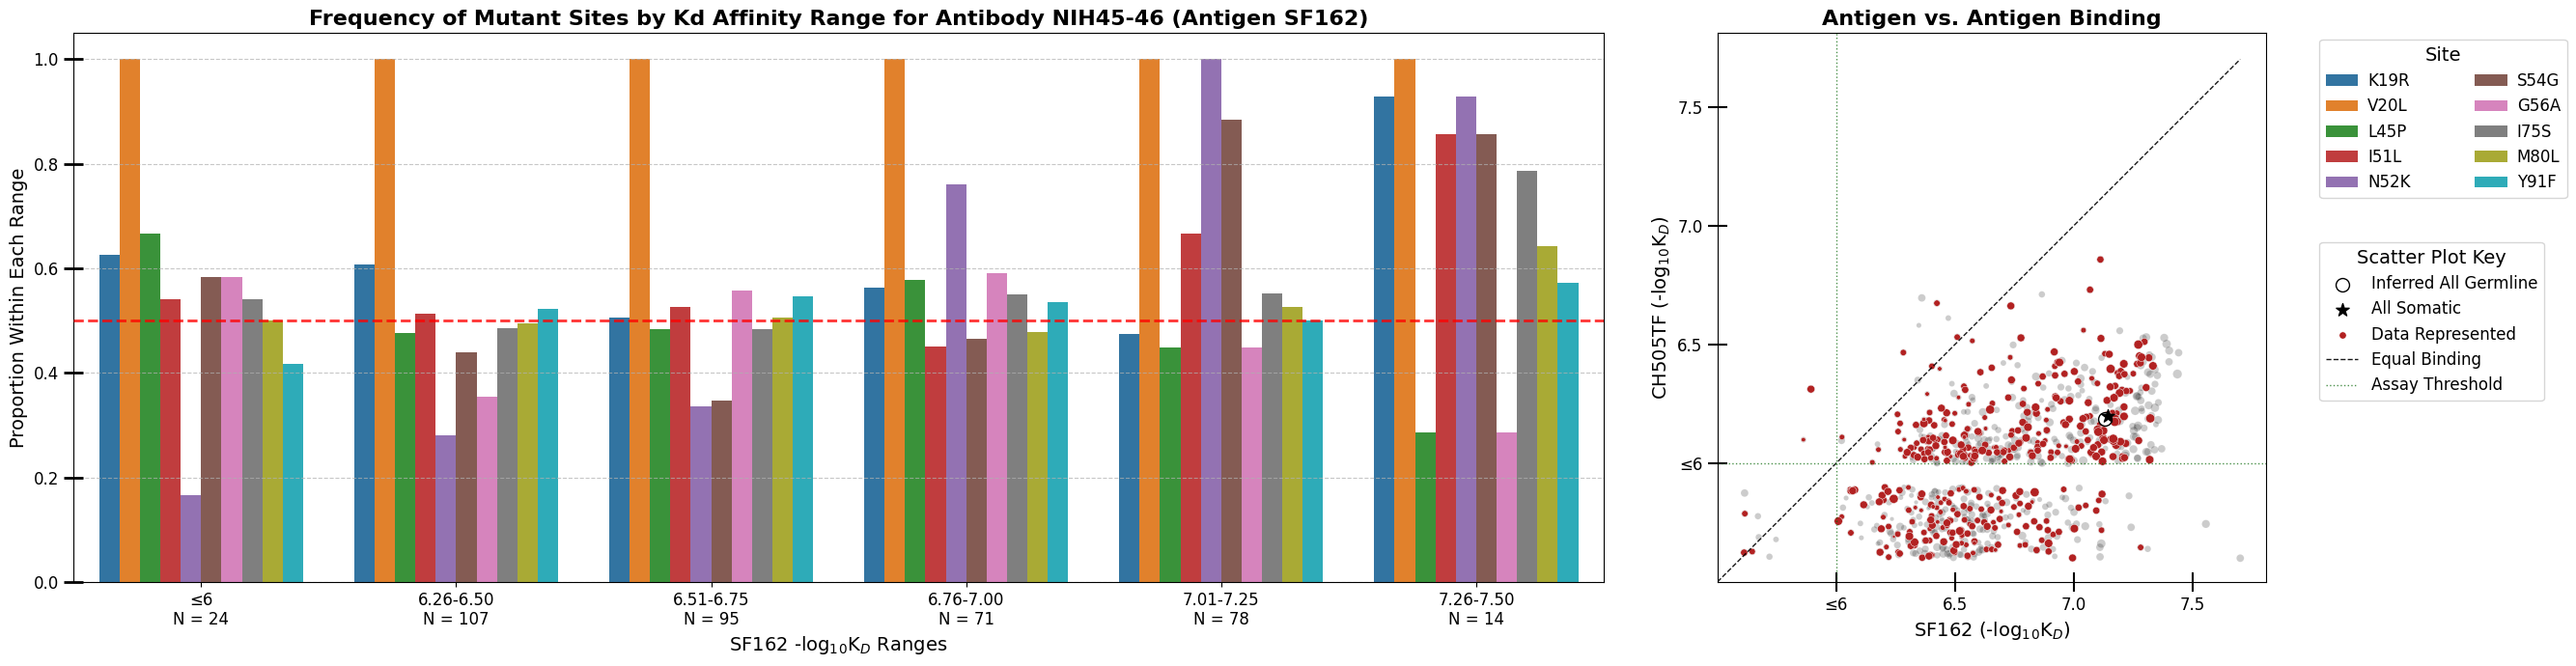

In [ ]:
antigen = 'SF162'
CH_range = [5.5, 10]
SF_range = [6,10]
plot_cols = ['raw_count','bin_fraction','total_fraction']
bnab = 'NIH45-46'


plot(bnab,antigen,CH_range,SF_range,plot_col = plot_cols[1],
     highlight_sites= [], highlight_color='k',m_sites = [2],highlight_lw=2,
     resolution = .25, color_l='tab10', save_fig = True, save_fig_title = 'Set 1' )

antigen = 'SF162'
CH_range = [5.5, 10]
SF_range = [6,10]
plot_cols = ['raw_count','bin_fraction','total_fraction']
bnab = 'NIH45-46'


plot(bnab,antigen,CH_range,SF_range,plot_col = plot_cols[1],
     highlight_sites= [], highlight_color='k',m_sites = [1],highlight_lw=2,
     resolution = .25, color_l='tab10', save_fig = True, save_fig_title = 'Set 1' )

